# Emergency Department Analytics
## Statistical Analysis and Predictive Modeling Using Python

### Project Objective

This project explores emergency department patient data to investigate:

1. Whether emergency department length of stay differs by admission status.
2. Whether average length of stay differs across triage severity levels.
3. Whether patient characteristics and operational measures can predict hospital admission.

The analysis uses Python for data exploration, statistical hypothesis testing, visualization, and predictive modeling.

### Tools
Python, pandas, SciPy, matplotlib, seaborn, and scikit-learn.

### Project Context
Educational case study using a practice dataset.

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Emergency Department dataset
file_path = "ed_project_data.csv"

df = pd.read_csv(file_path)

# Display the first five rows
df.head()

,visit_id,age,triage_level,arrival_hr,ed_los_hours,num_tests_ordered,admitted
0,1,65,High,3,7.39,2,1
1,2,86,Medium,14,3.12,1,1
2,3,43,Medium,18,6.03,3,0
3,4,85,Low,0,2.74,2,1
4,5,41,High,15,9.45,1,0


## 1. Data Exploration and Quality Assessment

Before conducting statistical analysis, I examine the dataset's structure, variable types, missing values, and duplicate records to identify potential data quality issues.

In [24]:
# Examine dataset dimensions
print("Dataset dimensions:", df.shape)

# Examine variable types
print("\nVariable types:")
print(df.dtypes)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate rows:", df.duplicated().sum())

# Check duplicate visit IDs
print("Duplicate visit IDs:", df["visit_id"].duplicated().sum())

# Summary statistics
df.describe(include="all")

Dataset dimensions: (400, 7)

Variable types:
visit_id               int64
age                    int64
triage_level             str
arrival_hr             int64
ed_los_hours         float64
num_tests_ordered      int64
admitted               int64
dtype: object

Missing values:
visit_id             0
age                  0
triage_level         0
arrival_hr           0
ed_los_hours         0
num_tests_ordered    0
admitted             0
dtype: int64

Duplicate rows: 0
Duplicate visit IDs: 0


,visit_id,age,triage_level,arrival_hr,ed_los_hours,num_tests_ordered,admitted
count,400.000000,400.000000,400,400.000000,400.000000,400.000000,400.000000
unique,NaN,NaN,3,NaN,NaN,NaN,NaN
top,NaN,NaN,Low,NaN,NaN,NaN,NaN
freq,NaN,NaN,163,NaN,NaN,NaN,NaN
mean,200.500000,53.552500,NaN,11.272500,5.027200,3.045000,0.312500
std,115.614301,20.540375,NaN,7.075195,3.203119,1.711812,0.464093
min,1.000000,18.000000,NaN,0.000000,0.360000,0.000000,0.000000
25%,100.750000,36.000000,NaN,5.000000,2.507500,2.000000,0.000000
50%,200.500000,54.000000,NaN,11.000000,4.535000,3.000000,0.000000
75%,300.250000,71.000000,NaN,17.000000,6.860000,4.000000,1.000000


### Initial Data Quality Findings

The dataset contains 400 emergency department visits and seven variables.

Initial validation found:
- No missing values.
- No duplicate records.
- No duplicate visit identifiers.
- An average patient age of approximately 53.6 years.
- An average emergency department length of stay of approximately 5.03 hours.
- An overall hospital admission rate of 31.25%.

These findings indicate that no missing-value imputation or duplicate removal is required. Additional range and consistency checks are needed before statistical analysis.

In [25]:
# Check for potentially invalid values

print("Negative ages:", (df["age"] < 0).sum())

print("Invalid arrival hours:",
      (~df["arrival_hr"].between(0, 23)).sum())

print("Negative lengths of stay:",
      (df["ed_los_hours"] < 0).sum())

print("Negative test counts:",
      (df["num_tests_ordered"] < 0).sum())

print("\nTriage categories:")
print(df["triage_level"].value_counts())

print("\nAdmission categories:")
print(df["admitted"].value_counts())

Negative ages: 0
Invalid arrival hours: 0
Negative lengths of stay: 0
Negative test counts: 0

Triage categories:
triage_level
Low       163
Medium    151
High       86
Name: count, dtype: int64

Admission categories:
admitted
0    275
1    125
Name: count, dtype: int64


## 2. Exploratory Data Analysis

This section examines the distribution of emergency department length of stay (LOS) and compares LOS between admitted and non-admitted patients.

The objective is to identify patterns, assess distribution shapes, and determine which statistical methods may be appropriate.

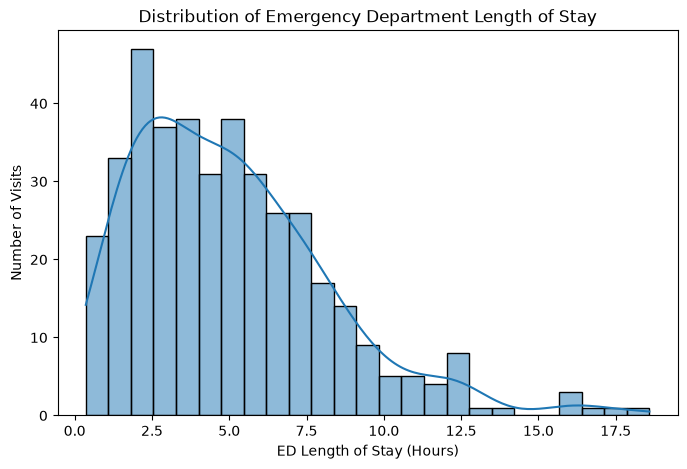

In [8]:
# Examine the overall distribution of ED length of stay

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="ed_los_hours",
    bins=25,
    kde=True
)

plt.title("Distribution of Emergency Department Length of Stay")
plt.xlabel("ED Length of Stay (Hours)")
plt.ylabel("Number of Visits")
plt.show()

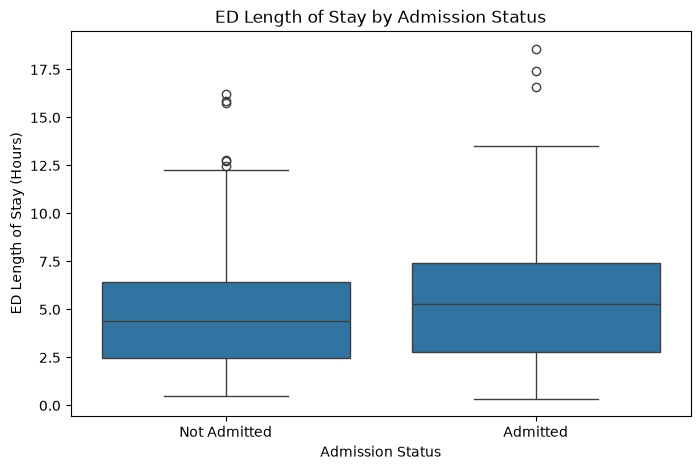

,count,mean,median,std
admitted,,,,
0,275,4.804582,4.39,2.996381
1,125,5.516960,5.31,3.580933


In [9]:
# Compare ED length of stay by admission status

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="admitted",
    y="ed_los_hours"
)

plt.xticks([0, 1], ["Not Admitted", "Admitted"])
plt.title("ED Length of Stay by Admission Status")
plt.xlabel("Admission Status")
plt.ylabel("ED Length of Stay (Hours)")
plt.show()

# Summary statistics by admission status
df.groupby("admitted")["ed_los_hours"].agg(
    ["count", "mean", "median", "std"]
)

## 3. Statistical Hypothesis Testing

### 3.1 Comparing ED Length of Stay by Admission Status

**Research question:** Is the mean emergency department length of stay different between patients who are admitted to the hospital and those who are not?

**Null hypothesis (H0):** The population mean ED length of stay is equal for admitted and non-admitted patients.

**Alternative hypothesis (H1):** The population means are different.

We use a two-sided Welch's independent-samples t-test because the two groups are independent (assuming each visit is an independent observation), and Welch's test does not require equal population variances.

We will examine the group distributions and sample sizes to assess whether the test is appropriate.

In [10]:
from scipy.stats import ttest_ind

# Separate the two groups
admitted = df.loc[
    df["admitted"] == 1, "ed_los_hours"
].dropna()

not_admitted = df.loc[
    df["admitted"] == 0, "ed_los_hours"
].dropna()

# Examine sample sizes, means, and standard deviations
print("Group summary statistics:")
print(
    df.groupby("admitted")["ed_los_hours"]
    .agg(["count", "mean", "std", "median"])
)

# Welch's independent two-sample t-test
t_stat, p_value = ttest_ind(
    admitted,
    not_admitted,
    equal_var=False
)

print("\nWelch's t-test")
print(f"t-statistic: {t_stat:.4f}")
print(f"p-value: {p_value:.4f}")

alpha = 0.05

if p_value < alpha:
    print("Reject H0: Evidence of a difference in population means.")
else:
    print("Fail to reject H0: Insufficient evidence of a difference.")

Group summary statistics:
          count      mean       std  median
admitted                                   
0           275  4.804582  2.996381    4.39
1           125  5.516960  3.580933    5.31

Welch's t-test
t-statistic: 1.9372
p-value: 0.0541
Fail to reject H0: Insufficient evidence of a difference.


### Interpretation

At the 5% significance level, we compare the p-value with 0.05 to determine whether there is sufficient statistical evidence that mean ED length of stay differs between admitted and non-admitted patients.

The result describes an association between admission status and length of stay. It does not establish that admission causes a longer ED stay.

### 3.2 Comparing ED Length of Stay Across Triage Levels

**Research question:** Does mean emergency department length of stay differ across Low, Medium, and High triage severity groups?

**Null hypothesis (H0):** All three population means are equal.

**Alternative hypothesis (H1):** At least one population mean differs.

A one-way ANOVA is used to compare mean ED length of stay across three independent groups.

The analysis assumes independent observations, approximately normal errors within groups, and equal population variances. We will consider these assumptions when interpreting the results.

In [11]:
from scipy.stats import f_oneway

# Separate ED length of stay by triage category
low = df.loc[
    df["triage_level"] == "Low", "ed_los_hours"
].dropna()

medium = df.loc[
    df["triage_level"] == "Medium", "ed_los_hours"
].dropna()

high = df.loc[
    df["triage_level"] == "High", "ed_los_hours"
].dropna()

# Summary statistics
print("LOS by triage level:")
print(
    df.groupby("triage_level")["ed_los_hours"]
    .agg(["count", "mean", "std"])
)

# One-way ANOVA
f_stat, p_value_anova = f_oneway(low, medium, high)

print("\nOne-way ANOVA")
print(f"F-statistic: {f_stat:.4f}")
print(f"p-value: {p_value_anova:.4f}")

if p_value_anova < 0.05:
    print("Reject H0: At least one population mean differs.")
else:
    print("Fail to reject H0: Insufficient evidence of differing means.")

LOS by triage level:
              count      mean       std
triage_level                           
High             86  5.010349  3.404456
Low             163  5.116994  3.149535
Medium          151  4.939868  3.161318

One-way ANOVA
F-statistic: 0.1208
p-value: 0.8862
Fail to reject H0: Insufficient evidence of differing means.


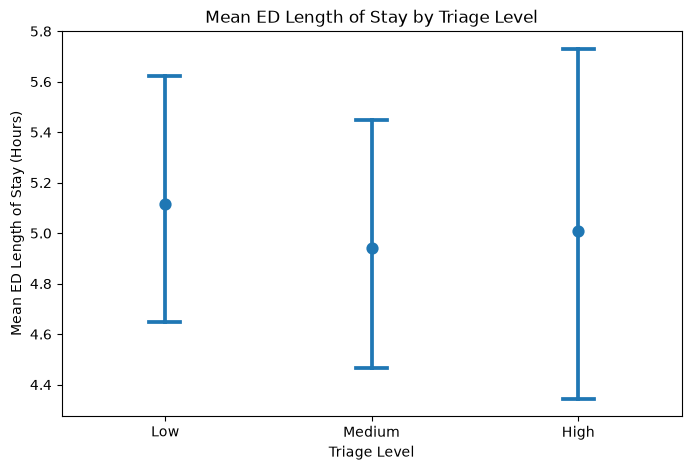

In [12]:
plt.figure(figsize=(8, 5))

sns.pointplot(
    data=df,
    x="triage_level",
    y="ed_los_hours",
    order=["Low", "Medium", "High"],
    errorbar=("ci", 95),
    capsize=0.15,
    linestyle="none"
)

plt.title("Mean ED Length of Stay by Triage Level")
plt.xlabel("Triage Level")
plt.ylabel("Mean ED Length of Stay (Hours)")
plt.show()

### Interpretation

Admitted patients had a higher sample mean ED length of stay (5.52 hours) than non-admitted patients (4.80 hours), a difference of approximately 0.71 hours.

Welch's two-sample t-test yielded t = 1.9372 and p = 0.0541. At the 5% significance level, we fail to reject the null hypothesis.

The observed difference is not statistically significant at this threshold. This does not establish that the population means are equal.

### Interpretation

Mean ED length of stay was 5.12 hours for Low triage, 4.94 hours for Medium triage, and 5.01 hours for High triage.

One-way ANOVA yielded F = 0.1208 and p = 0.8862.

At the 5% significance level, we fail to reject the null hypothesis. There is insufficient evidence that mean ED length of stay differs across the three triage groups.

## 4. Predictive Modeling: Logistic Regression

### Research Question

Can patient age, emergency department length of stay, and number of diagnostic tests help predict whether a patient will be admitted to the hospital?

### Analytical Approach

Hospital admission is a binary outcome:
- 0 = Not admitted
- 1 = Admitted

Logistic regression is appropriate because it models the probability of a binary outcome.

The dataset will be divided into:
- 80% training data to fit the model.
- 20% testing data to evaluate its performance on unseen observations.

We will use stratified sampling to preserve approximately the same admission proportions in both datasets.

Model performance will be evaluated using accuracy, sensitivity, specificity, a confusion matrix, and ROC-AUC.

In [13]:
from sklearn.model_selection import train_test_split

# Define predictors and target
X = df[["age", "ed_los_hours", "num_tests_ordered"]]
y = df["admitted"]

# Split into training and testing datasets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print("\nTraining admission proportions:")
print(y_train.value_counts(normalize=True))

print("\nTesting admission proportions:")
print(y_test.value_counts(normalize=True))

Training observations: 320
Testing observations: 80

Training admission proportions:
admitted
0    0.6875
1    0.3125
Name: proportion, dtype: float64

Testing admission proportions:
admitted
0    0.6875
1    0.3125
Name: proportion, dtype: float64


In [14]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Build the modeling pipeline
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

# Fit using training data only
logistic_model.fit(X_train, y_train)

# Predict on unseen test data
y_pred = logistic_model.predict(X_test)

# Estimate admission probabilities
y_prob = logistic_model.predict_proba(X_test)[:, 1]

print("Logistic regression model trained successfully.")

Logistic regression model trained successfully.


Accuracy: 0.688
Sensitivity: 0.000
Specificity: 1.000
ROC-AUC: 0.545
Majority-class baseline accuracy: 0.688


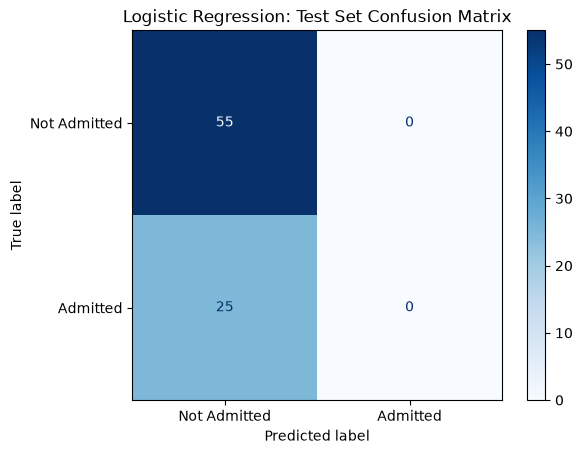

In [15]:
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    RocCurveDisplay
)

# Evaluate predictions on the test set
accuracy = accuracy_score(y_test, y_pred)
sensitivity = recall_score(y_test, y_pred, zero_division=0)

tn, fp, fn, tp = confusion_matrix(
    y_test, y_pred, labels=[0, 1]
).ravel()

specificity = tn / (tn + fp)
auc_score = roc_auc_score(y_test, y_prob)

print(f"Accuracy: {accuracy:.3f}")
print(f"Sensitivity: {sensitivity:.3f}")
print(f"Specificity: {specificity:.3f}")
print(f"ROC-AUC: {auc_score:.3f}")

# Compare with a simple baseline
baseline_accuracy = (y_test == 0).mean()
print(f"Majority-class baseline accuracy: {baseline_accuracy:.3f}")

# Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=["Not Admitted", "Admitted"],
    cmap="Blues"
)

plt.title("Logistic Regression: Test Set Confusion Matrix")
plt.show()

### Logistic Regression: Model Evaluation

The logistic regression model achieved 68.8% accuracy on the held-out test dataset, identical to the majority-class baseline.

However, the confusion matrix revealed that the model classified every patient as not admitted. Consequently, sensitivity was 0%, while specificity was 100%.

The ROC-AUC was 0.545, indicating weak discrimination between admitted and non-admitted patients.

These results demonstrate why accuracy alone is insufficient for evaluating a classification model, particularly when the outcome classes are imbalanced.

The current model is not suitable for identifying patients at risk of hospital admission.

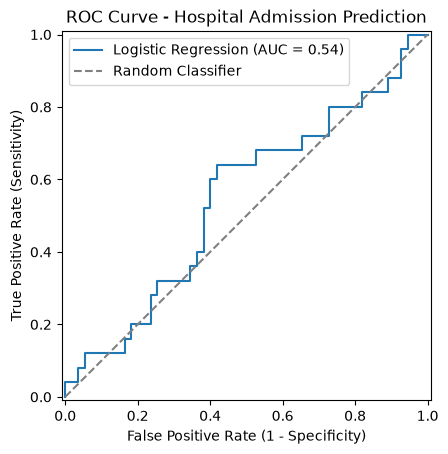

In [16]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    name="Logistic Regression"
)

plt.plot([0, 1], [0, 1], "--", color="gray",
         label="Random Classifier")

plt.title("ROC Curve - Hospital Admission Prediction")
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity)")
plt.legend()
plt.show()

## 5. Comparing Classification Models

### Research Question

Can nonlinear classification models improve hospital admission prediction compared with logistic regression?

### Analytical Approach

We compare three classification methods:

1. Logistic Regression — models admission probability using a linear combination of predictors on the log-odds scale.
2. Decision Tree — captures nonlinear relationships and interactions through decision rules.
3. Random Forest — combines multiple decision trees to improve prediction stability.

All three models use the same training and testing datasets.

We compare accuracy, sensitivity, specificity, and ROC-AUC. Particular attention is given to sensitivity because failing to identify admitted patients is an important limitation.

In [17]:
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(
    max_depth=4,
    min_samples_leaf=10,
    random_state=42
)

tree_model.fit(X_train, y_train)

tree_pred = tree_model.predict(X_test)
tree_prob = tree_model.predict_proba(X_test)[:, 1]

print("Decision Tree trained successfully.")

Decision Tree trained successfully.


In [18]:
from sklearn.ensemble import RandomForestClassifier

forest_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=5,
    min_samples_leaf=5,
    random_state=42
)

forest_model.fit(X_train, y_train)

forest_pred = forest_model.predict(X_test)
forest_prob = forest_model.predict_proba(X_test)[:, 1]

print("Random Forest trained successfully.")

Random Forest trained successfully.


In [19]:
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    roc_auc_score,
    confusion_matrix
)

def evaluate_model(name, actual, predicted, probabilities):
    tn, fp, fn, tp = confusion_matrix(
        actual, predicted, labels=[0, 1]
    ).ravel()

    return {
        "Model": name,
        "Accuracy": accuracy_score(actual, predicted),
        "Sensitivity": recall_score(
            actual, predicted, zero_division=0
        ),
        "Specificity": tn / (tn + fp),
        "ROC-AUC": roc_auc_score(actual, probabilities)
    }

results = pd.DataFrame([
    evaluate_model(
        "Logistic Regression", y_test, y_pred, y_prob
    ),
    evaluate_model(
        "Decision Tree", y_test, tree_pred, tree_prob
    ),
    evaluate_model(
        "Random Forest", y_test, forest_pred, forest_prob
    )
])

results.round(3)

,Model,Accuracy,Sensitivity,Specificity,ROC-AUC
0,Logistic Regression,0.688,0.00,1.000,0.545
1,Decision Tree,0.625,0.32,0.764,0.635
2,Random Forest,0.688,0.00,1.000,0.645


### Model Comparison and Interpretation

Three classification models were evaluated using the same held-out test dataset of 80 emergency department visits.

Logistic Regression and Random Forest both achieved 68.8% accuracy, equivalent to the majority-class baseline. Neither model identified any admitted patients using the default classification threshold of 0.5.

The Decision Tree achieved lower overall accuracy (62.5%) but identified 32% of admitted patients, demonstrating a trade-off between sensitivity and specificity.

Random Forest achieved the highest ROC-AUC (0.645), followed by Decision Tree (0.635) and Logistic Regression (0.545).

These findings illustrate that accuracy alone is not sufficient to evaluate classification performance. Model selection should consider the intended operational objective, the consequences of false negatives and false positives, and performance across different classification thresholds.

Overall, predictive performance remains limited, and none of these models is ready for clinical use.

             Feature  Importance
0                age    0.416004
1       ed_los_hours    0.406377
2  num_tests_ordered    0.177619


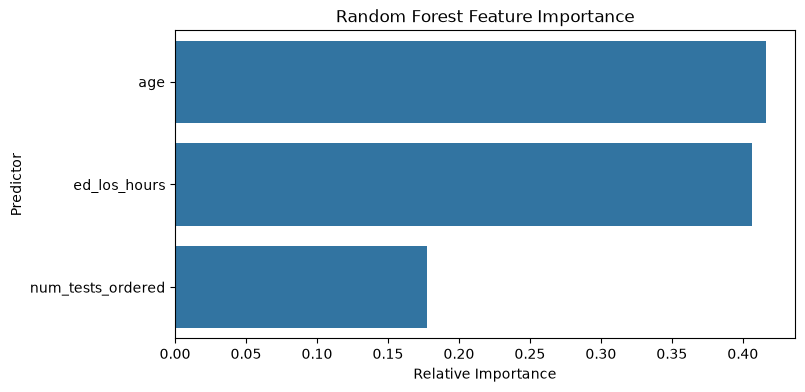

In [20]:
# Random Forest feature importance

importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": forest_model.feature_importances_
}).sort_values("Importance", ascending=False)

print(importance)

plt.figure(figsize=(8, 4))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Relative Importance")
plt.ylabel("Predictor")
plt.show()

### Random Forest Feature Importance

The Random Forest assigned the highest relative importance to patient age (41.6%) and emergency department length of stay (40.6%). The number of diagnostic tests ordered contributed 17.8%.

These impurity-based importance measures describe how much each predictor contributed to the model's splitting decisions during training.

They do not establish causal relationships, indicate the direction of an association, or guarantee predictive usefulness on unseen data.

Given the model's modest ROC-AUC of 0.645, these findings should be interpreted cautiously.

In [21]:
# Compare classification thresholds for Random Forest

threshold_results = []

for threshold in [0.20, 0.25, 0.30, 0.35, 0.40, 0.50]:

    predictions = (forest_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Sensitivity": tp / (tp + fn),
        "Specificity": tn / (tn + fp),
        "False Positives": fp,
        "False Negatives": fn
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(3))

,Threshold,Accuracy,Sensitivity,Specificity,False Positives,False Negatives
0,0.20,0.325,1.00,0.018,54,0
1,0.25,0.488,0.92,0.291,39,2
2,0.30,0.600,0.72,0.545,25,7
3,0.35,0.638,0.32,0.782,12,17
4,0.40,0.638,0.12,0.873,7,22
5,0.50,0.688,0.00,1.000,0,25


### Classification Threshold Analysis

The Random Forest's performance was evaluated at classification thresholds ranging from 0.20 to 0.50.

At the default threshold of 0.50, the model failed to identify any admitted patients (0% sensitivity), although specificity was 100%.

Reducing the threshold to 0.30 increased sensitivity to 72%, identifying 18 of the 25 admitted patients. However, specificity decreased to 54.5%, resulting in 25 false positives.

At a threshold of 0.20, sensitivity reached 100%, but specificity fell to 1.8%.

These results illustrate the trade-off between sensitivity and specificity.

The appropriate threshold depends on the intended use of the model and the relative consequences of false positives and false negatives.

This analysis is exploratory. Thresholds were compared using the test set to demonstrate their behavior, not to select an optimal threshold. A production modeling workflow would select the threshold using training or validation data and evaluate it on an untouched test set.

## 6. Conclusions and Limitations

### Key Findings

1. Admitted patients had a higher average ED length of stay than non-admitted patients (5.52 versus 4.80 hours), but the difference did not reach statistical significance at the 5% level (Welch's t-test, p = 0.0541).

2. Mean ED length of stay did not differ significantly across the three triage levels (ANOVA, p = 0.8862).

3. The Random Forest achieved the highest test ROC-AUC (0.645), but none of the three classification models demonstrated strong predictive performance.

4. Classification threshold selection substantially affected sensitivity and specificity. This highlights the importance of evaluating models according to their intended operational purpose rather than relying on accuracy alone.

### Limitations

- The dataset contains only 400 observations and was provided for educational purposes.
- Predictive performance was evaluated on a single 80-observation test set.
- Model hyperparameters were not systematically optimized using cross-validation.
- ED length of stay and diagnostic test counts may not be available at the time an early admission prediction is needed.
- The analyses are observational and do not establish causal relationships.
- The findings should not be generalized to actual hospital populations without further validation.

### Overall Conclusion

This project demonstrates a complete exploratory analytical workflow, from data validation and statistical hypothesis testing to predictive modeling and model evaluation.

The results emphasize the importance of selecting appropriate statistical methods, interpreting uncertainty, and considering the practical consequences of model predictions.

In [22]:
import os
print(os.getcwd())


C:\Users\laila
